In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Importar el módulo robusto basado en Chen que acabas de proporcionar
# (Asegúrate de que 'Robusted_Chen_biAA.py' esté en la misma carpeta o accesible en el path)
from src.Robusted_Chen_biAA_mxnx1 import robust_biarchetypal_analysis_huber_cellwise

np.set_printoptions(precision=4, suppress=True)

In [2]:
# -------------------------------------------------------------------------
# 1. GENERACIÓN DE DATOS SINTÉTICOS (N=150, M=30, k=4, c=3)
# -------------------------------------------------------------------------
rng = np.random.default_rng(100)

N_samples, M_features = 150, 30
k_row_archetypes = 4     
c_col_archetypes = 3     

# Estructura latente limpia
true_Z = rng.uniform(low=0.2, high=0.8, size=(k_row_archetypes, c_col_archetypes))
true_alpha = rng.dirichlet(np.ones(k_row_archetypes), size=N_samples)
true_gamma = rng.dirichlet(np.ones(k_row_archetypes), size=M_features).T # Nota: ajustado dimensionalmente si aplica

# Matriz sintética base limpia (asegurando dimensiones correctas para alpha @ Z @ gamma)
# true_alpha: (150, 4), true_Z: (4, 3), true_gamma: (3, 30) -> (150, 30)
true_gamma_fixed = rng.dirichlet(np.ones(c_col_archetypes), size=M_features).T # (3, 30)
X_clean = true_alpha @ true_Z @ true_gamma_fixed

# Inyección de outliers
X = X_clean.copy()
n_outliers = 25
outlier_mask_real = np.zeros((N_samples, M_features), dtype=bool)

row_idx = rng.integers(0, N_samples, size=n_outliers)
col_idx = rng.integers(0, M_features, size=n_outliers)

for r, c_idx in zip(row_idx, col_idx):
    X[r, c_idx] += rng.uniform(10.0, 20.0)
    outlier_mask_real[r, c_idx] = True

print("="*60)
print("TEST: EVALUACIÓN DE BiAA ROBUSTO (CHEN / HUBER)")
print("="*60)
print(f"Dimensiones de X: {X.shape}")
print(f"Arquetipos Filas (k): {k_row_archetypes} | Arquetipos Columnas (c): {c_col_archetypes}")
print(f"Outliers de celdas inyectados: {np.sum(outlier_mask_real)}")

TEST: EVALUACIÓN DE BiAA ROBUSTO (CHEN / HUBER)
Dimensiones de X: (150, 30)
Arquetipos Filas (k): 4 | Arquetipos Columnas (c): 3
Outliers de celdas inyectados: 25


In [5]:
# -------------------------------------------------------------------------
# 2. EJECUCIÓN DEL ALGORITMO
# -------------------------------------------------------------------------
print("\nEjecutando robust_biarchetypal_analysis_huber...")

alpha_huber, beta_huber, gamma_huber, theta_huber, Z_huber, effective_weights = robust_biarchetypal_analysis_huber_cellwise(
    X,
    k=k_row_archetypes,
    c=c_col_archetypes,
    max_robust_iter=20,
    max_inner_iter=50,
    epsilon=0.01,
    tol=1e-5,
    seed=100,
    verbose=False
)


Ejecutando robust_biarchetypal_analysis_huber...


In [6]:
# -------------------------------------------------------------------------
# 3. MÉTRICAS Y RENDIMIENTO
# -------------------------------------------------------------------------
X_hat_huber = alpha_huber @ Z_huber @ gamma_huber

# Filas que contienen al menos un outlier real
rows_with_outliers = np.any(outlier_mask_real, axis=1)

# Filas penalizadas por Huber (ej. peso menor a un umbral como 0.8)
rows_penalized = effective_weights < 0.8

# Error de reconstrucción respecto a la matriz limpia
error_vs_clean = np.mean((X_clean - X_hat_huber)**2)

print("\n--- RESULTADOS DE RENDIMIENTO ---")
print(f"Filas totales con outliers: {np.sum(rows_with_outliers)}")
print(f"Filas penalizadas por el modelo Huber: {np.sum(rows_penalized)}")
print(f"MSE de la reconstrucción respecto a X_limpia: {error_vs_clean:.6f}")


--- RESULTADOS DE RENDIMIENTO ---
Filas totales con outliers: 23
Filas penalizadas por el modelo Huber: 1924
MSE de la reconstrucción respecto a X_limpia: 0.001722


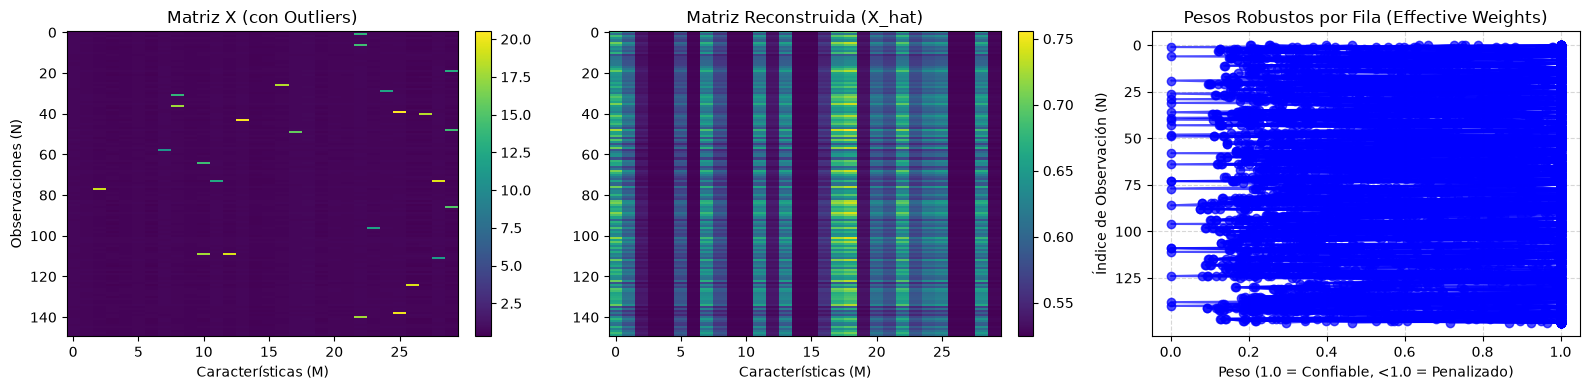

In [7]:
# -------------------------------------------------------------------------
# 4. VISUALIZACIÓN DE PESOS Y RENDIMIENTO
# -------------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# 1. Matriz de datos originales contaminados
im0 = axes[0].imshow(X, aspect='auto', cmap='viridis', interpolation='nearest')
axes[0].set_title("Matriz X (con Outliers)")
axes[0].set_xlabel("Características (M)")
axes[0].set_ylabel("Observaciones (N)")
fig.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)

# 2. Matriz reconstruida
im1 = axes[1].imshow(X_hat_huber, aspect='auto', cmap='viridis', interpolation='nearest')
axes[1].set_title("Matriz Reconstruida (X_hat)")
axes[1].set_xlabel("Características (M)")
fig.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

# 3. Pesos de Huber asignados por cada observación (fila)
axes[2].plot(effective_weights, np.arange(N_samples), marker='o', linestyle='-', color='b', alpha=0.7)
axes[2].set_yticks(np.arange(0, N_samples, 25))
axes[2].set_title("Pesos Robustos por Fila (Effective Weights)")
axes[2].set_xlabel("Peso (1.0 = Confiable, <1.0 = Penalizado)")
axes[2].set_ylabel("Índice de Observación (N)")
axes[2].invert_yaxis() # Para alinear visualmente con la matriz de arriba
axes[2].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()